In [ ]:
import pandas as pd

file_name = 'datadump_s5-000.csv'

df = pd.read_csv(file_name)

df.head()

,dateid,platform,gamemode,mapname,matchid,roundnumber,objectivelocation,winrole,endroundreason,roundduration,...,primarygrip,primaryunderbarrel,primarybarrel,secondaryweapon,secondaryweapontype,secondarysight,secondarygrip,secondaryunderbarrel,secondarybarrel,secondarygadget
0,20170212,PC,HOSTAGE,CLUB_HOUSE,1.522381e+09,1.0,STRIP_CLUB,Defender,AttackersKilledHostage,124.0,...,Vertical,NaN,Compensator,5.7_USG,Pistols,NaN,NaN,NaN,NaN,IMPACT_GRENADE
1,20170212,PC,HOSTAGE,CLUB_HOUSE,1.522381e+09,4.0,CHURCH,Defender,AttackersEliminated,217.0,...,Vertical,Laser,Suppressor,P12,Pistols,NaN,NaN,Laser,Suppressor,DEPLOYABLE_SHIELD
2,20170212,PC,HOSTAGE,CLUB_HOUSE,1.522381e+09,3.0,CHURCH,Defender,AttackersEliminated,160.0,...,NaN,NaN,NaN,MK1_9mm,Pistols,NaN,NaN,NaN,NaN,DEPLOYABLE_SHIELD
3,20170212,PC,HOSTAGE,CLUB_HOUSE,1.522381e+09,4.0,CHURCH,Defender,AttackersEliminated,217.0,...,NaN,NaN,MuzzleBrake,PRB92,Pistols,NaN,NaN,NaN,NaN,IMPACT_GRENADE
4,20170212,PC,HOSTAGE,CLUB_HOUSE,1.522381e+09,6.0,BEDROOM,Attacker,DefendersEliminated,143.0,...,Vertical,Laser,Suppressor,P12,Pistols,NaN,NaN,Laser,Suppressor,DEPLOYABLE_SHIELD


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

df = pd.read_csv('datadump_s5-000.csv')
print("Ready")

Ready


In [ ]:
ml_data = df[['mapname', 'objectivelocation', 'roundduration', 'winrole']].dropna()

le_map = LabelEncoder()
le_obj = LabelEncoder()
ml_data['map_encoded'] = le_map.fit_transform(ml_data['mapname'])
ml_data['obj_encoded'] = le_obj.fit_transform(ml_data['objectivelocation'])

X = ml_data[['map_encoded', 'obj_encoded', 'roundduration']]
y = ml_data['winrole']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(" Machine Learning:", accuracy_score(y_test, y_pred))

 Machine Learning: 0.6971171082507926


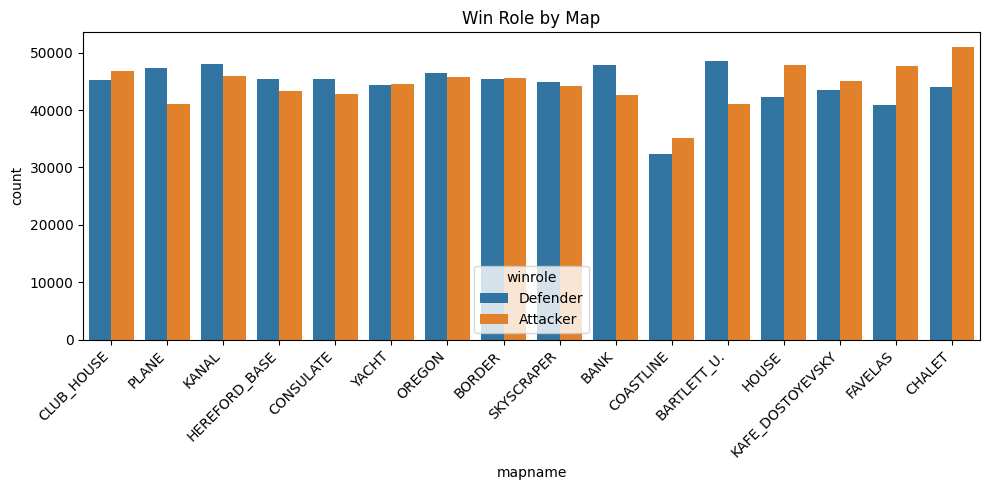

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='mapname', hue='winrole')
plt.xticks(rotation=45, ha='right')
plt.title('Win Role by Map')
plt.tight_layout()
plt.show()

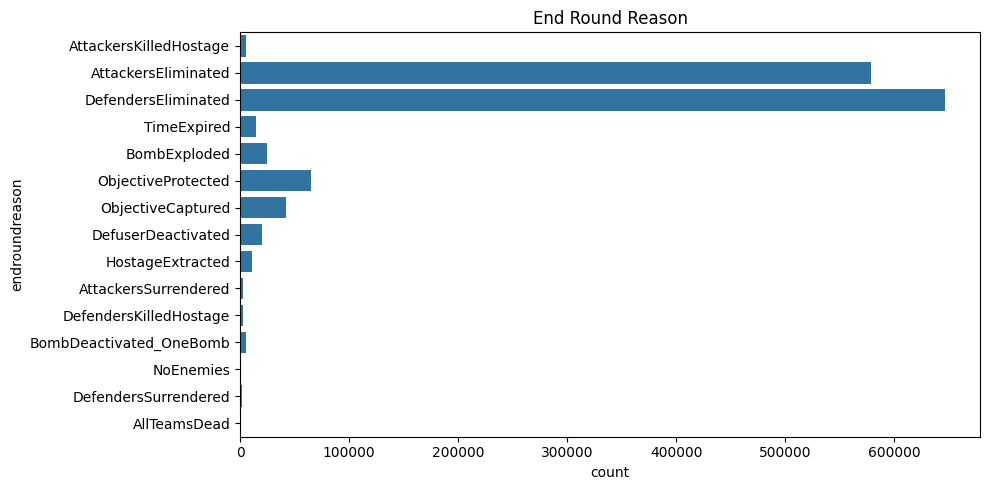

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='endroundreason')
plt.title('End Round Reason')
plt.tight_layout()
plt.show()